# Logistic Regression on the Breast Cancer Dataset

A step-by-step walkthrough of the simplest possible `scikit-learn` logistic
regression demo (same model as `bcancer.py`), using the built-in
Breast Cancer Wisconsin dataset. Along the way we'll print a few things to
see what's going on, and plot the logistic (sigmoid) "S-curve" two
different ways.

## 1. Imports

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

## 2. Load the data

`load_breast_cancer()` returns 30 numeric features per sample (things like
cell radius, texture, concavity, ...) and a binary target: `0 = malignant`,
`1 = benign`.

In [13]:
data = load_breast_cancer()
# print(data)

X, y = data.data, data.target

print("Features:", list(data.feature_names))
print("Classes:", list(data.target_names))
print("X shape:", X.shape)
print("Class balance (0=malignant, 1=benign):", np.bincount(y))

Features: [np.str_('mean radius'), np.str_('mean texture'), np.str_('mean perimeter'), np.str_('mean area'), np.str_('mean smoothness'), np.str_('mean compactness'), np.str_('mean concavity'), np.str_('mean concave points'), np.str_('mean symmetry'), np.str_('mean fractal dimension'), np.str_('radius error'), np.str_('texture error'), np.str_('perimeter error'), np.str_('area error'), np.str_('smoothness error'), np.str_('compactness error'), np.str_('concavity error'), np.str_('concave points error'), np.str_('symmetry error'), np.str_('fractal dimension error'), np.str_('worst radius'), np.str_('worst texture'), np.str_('worst perimeter'), np.str_('worst area'), np.str_('worst smoothness'), np.str_('worst compactness'), np.str_('worst concavity'), np.str_('worst concave points'), np.str_('worst symmetry'), np.str_('worst fractal dimension')]
Classes: [np.str_('malignant'), np.str_('benign')]
X shape: (569, 30)
Class balance (0=malignant, 1=benign): [212 357]


## 3. Train/test split

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)

print("Train size:", X_train.shape[0])
print("Test size:", X_test.shape[0])

Train size: 426
Test size: 143


## 4. Fit the logistic regression model

This is the same model as `bcancer.py`: one `LogisticRegression` fit on all
30 features. `max_iter` is bumped up from the default (100) because the
features aren't scaled, so the solver needs more iterations to converge.

In [15]:
model = LogisticRegression(max_iter=5000)
model.fit(X_train, y_train)

print("Test accuracy (all 30 features):", model.score(X_test, y_test))

Test accuracy (all 30 features): 0.951048951048951


## 5. The sigmoid "S-curve" — does it only work for one predictor?

Logistic regression computes a single number per sample,
$z = w \cdot x + b$ (the "decision function"), then squashes it into a
probability with the sigmoid function:

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

Since $z$ is always a *single number* — no matter how many features went
into computing it — the S-curve of probability vs. $z$ always looks clean,
even with 30 predictors. That's plot **A** below.

But if you instead plot probability against one *raw, original* feature
(like "mean radius") while a model uses all 30 features, the other 29
features add noise/scatter and it won't look like a clean S. To see the
classic textbook S-curve against a real feature axis, you need a model
fit on just that *one* feature. That's plot **B** below.

### Plot A: probability vs. decision function `z` (any number of predictors)

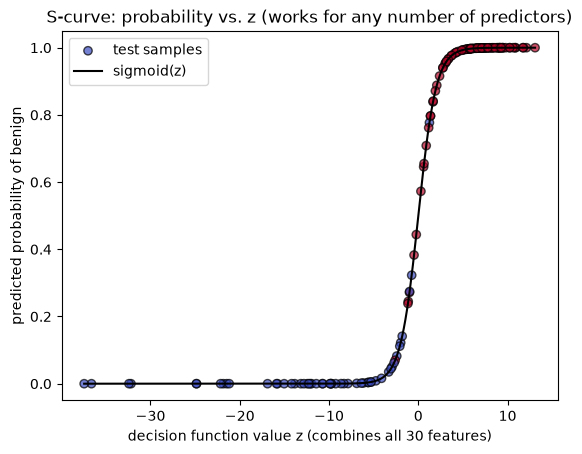

In [16]:
z_test = model.decision_function(X_test)
proba_test = model.predict_proba(X_test)[:, 1]

z_line = np.linspace(z_test.min(), z_test.max(), 300)
sigmoid_line = 1 / (1 + np.exp(-z_line))

plt.figure()
plt.scatter(z_test, proba_test, c=y_test, cmap="coolwarm", edgecolor="k", alpha=0.7, label="test samples")
plt.plot(z_line, sigmoid_line, color="black", label="sigmoid(z)")
plt.xlabel("decision function value z (combines all 30 features)")
plt.ylabel("predicted probability of benign")
plt.title("S-curve: probability vs. z (works for any number of predictors)")
plt.legend()
plt.show()

### Plot B: single-predictor S-curves for every feature

Rather than picking just one feature, let's fit a brand-new logistic regression for *each* of the 30 features individually (including "mean radius") and plot every resulting S-curve in a grid.

**Why matplotlib instead of seaborn?** Seaborn's `sns.regplot(logistic=True)` can draw a single logistic S-curve for you, but under the hood it fits its own curve with `statsmodels`, not the `sklearn` `LogisticRegression` models we're already training — and it would pull in an extra dependency just for this. Looping over features with matplotlib keeps everything using the same `sklearn` model objects and tools we already have, and scales just as easily to 30 small subplots.

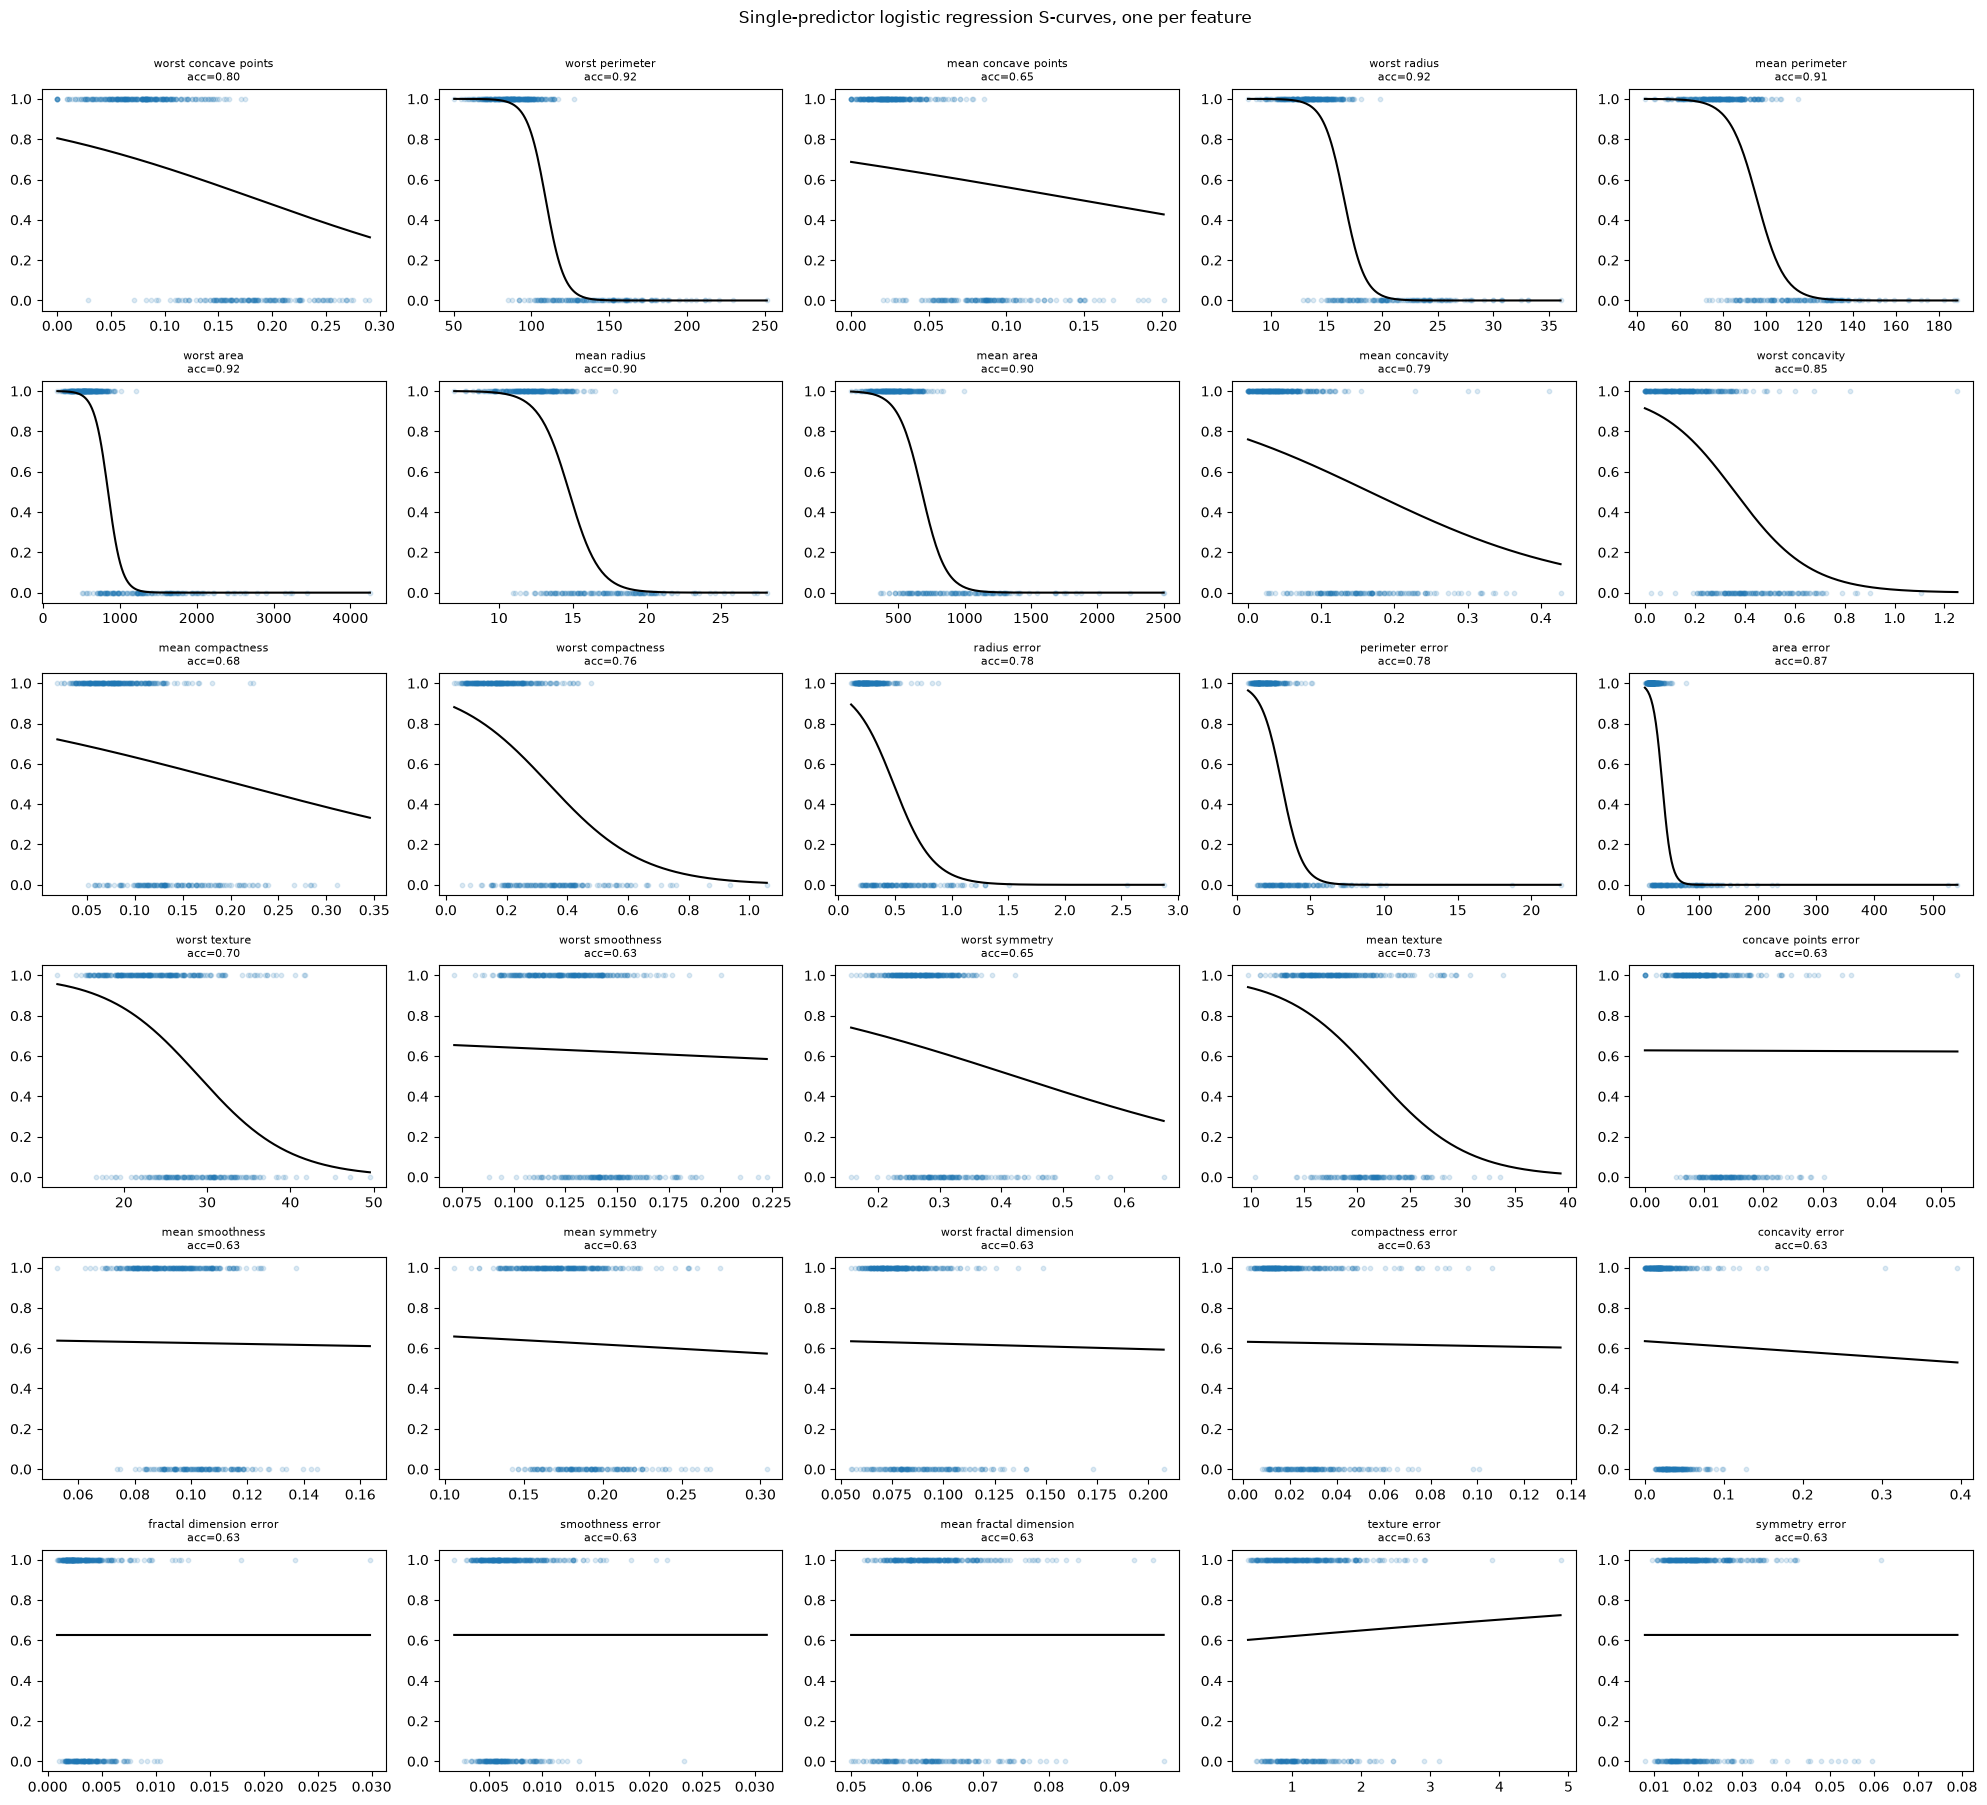

In [17]:
n_features = X.shape[1]
n_cols = 5
n_rows = int(np.ceil(n_features / n_cols))

correlations = [np.corrcoef(X[:, i], y)[0, 1] for i in range(n_features)]

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3 * n_rows))
axes = axes.ravel()

# sort features by how strongly they correlate with the target, most informative first
order = np.argsort(-np.abs(correlations))

for plot_pos, feature_idx in enumerate(order):
    ax = axes[plot_pos]
    feature_name = data.feature_names[feature_idx]

    X_i = X[:, [feature_idx]]
    Xi_train, Xi_test, yi_train, yi_test = train_test_split(X_i, y, random_state=0)

    feature_model = LogisticRegression(max_iter=5000)
    feature_model.fit(Xi_train, yi_train)
    acc = feature_model.score(Xi_test, yi_test)

    x_line = np.linspace(X_i.min(), X_i.max(), 200).reshape(-1, 1)
    proba_line = feature_model.predict_proba(x_line)[:, 1]

    ax.scatter(Xi_train, yi_train, alpha=0.15, s=10)
    ax.plot(x_line, proba_line, color="black")
    ax.set_title(f"{feature_name}\nacc={acc:.2f}", fontsize=8)
    ax.set_ylim(-0.05, 1.05)

for j in range(n_features, len(axes)):
    axes[j].axis("off")

fig.suptitle("Single-predictor logistic regression S-curves, one per feature", y=1.0)
fig.tight_layout()
plt.show()

### Reading the small multiples: why are some S-curves flat?

The baseline rate in this dataset is about **62.7% benign**. A feature's curve
goes flat at that baseline when the feature has (close to) zero correlation
with the target — the optimizer can't find a useful slope, so the best fit
is "ignore this feature and just predict the overall class rate," no matter
what `x` is. That's exactly what a flat line *is*: the model falling back to
the marginal probability because that one feature alone carries no signal.

A few patterns worth noticing:

- **Size and shape-irregularity features win.** The steepest, cleanest
  S-curves belong to `worst`/`mean` versions of radius, perimeter, area,
  concavity, and concave points — each alone gets 90%+ test accuracy.
  Bigger, more irregular cell nuclei being linked to malignancy matches how
  pathologists actually read these slides.
- **`*_error` features tend to be flat.** This dataset has three versions of
  each measurement: `mean`, `error` (variability across the image), and
  `worst` (largest value seen). The `error` features describe *measurement
  noise*, not the tumor's actual characteristics — so most of them carry
  little or no signal on their own.
- **The negative correlations make sense.** `scikit-learn` encodes
  `0 = malignant`, `1 = benign`, so "bigger/more irregular → lower `y`" is
  exactly "bigger/more irregular → more likely malignant."
- **Flat here doesn't prove a feature is useless** in combination with
  others (this view can't show interaction effects) — but for this dataset,
  the single-feature story largely matches what the full 30-feature model
  relies on too.

## 7. Confusion matrix

Accuracy (a single percentage) hides *what kind* of mistakes a classifier
makes. A **confusion matrix** breaks predictions down into a small table:

|  | predicted malignant | predicted benign |
|---|---|---|
| **actual malignant** | correctly caught | **missed cancer** |
| **actual benign** | false alarm | correctly cleared |

In classic ML terms (treating "malignant" as the positive/disease class,
even though `scikit-learn`'s numeric label for it happens to be `0`):

- **True Positive (TP)** — malignant, correctly predicted malignant.
- **True Negative (TN)** — benign, correctly predicted benign.
- **False Positive (FP)** — benign, incorrectly predicted malignant (a false alarm).
- **False Negative (FN)** — malignant, incorrectly predicted benign (a missed cancer).

This matters because the two kinds of mistakes are not equally costly: a
false alarm (FP) means more tests and worry, but a **missed cancer (FN)** is
the far more dangerous error. Two models can have the *same* accuracy while
making very different trade-offs between these error types — a confusion
matrix is how you'd actually see that.

Confusion matrix (rows = actual, columns = predicted):
[[52  1]
 [ 6 84]]
Row/column order: [np.str_('malignant'), np.str_('benign')]


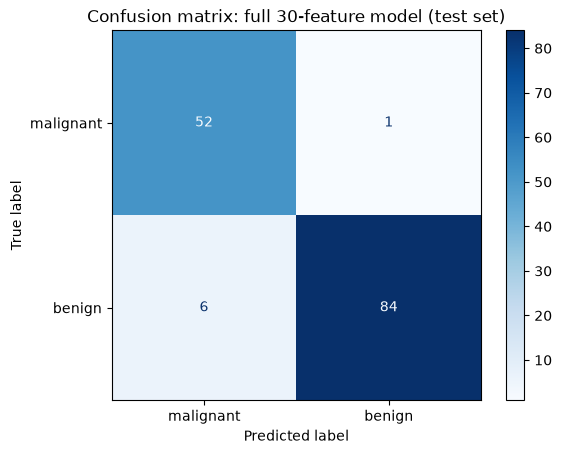

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred = model.predict(X_test)
cm = confusion_matrix(y_test, y_pred)

print("Confusion matrix (rows = actual, columns = predicted):")
print(cm)
print("Row/column order:", list(data.target_names))

ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=data.target_names).plot(cmap="Blues")
plt.title("Confusion matrix: full 30-feature model (test set)")
plt.show()

Reading this run's matrix: out of the malignant tumors in the test set,
almost all were caught, but a handful were predicted benign — those are the
false negatives (missed cancers) mentioned above, and they're the main
reason to look past the single accuracy number (95%) and check the matrix
whenever the cost of a missed case outweighs the cost of a false alarm.

## 8. Recap

- The full 30-feature model and every single-feature model use the same
  `LogisticRegression` — the only difference is how many columns of `X` go in.
- The sigmoid S-curve always exists mathematically (probability vs. `z`),
  but it only looks like a clean S-curve *against a raw feature axis* when
  that feature is the model's only input; flat curves mean that one feature
  alone carries no signal, so the model falls back to the baseline class rate.
- The grid shows that "worst"/"mean" size and concavity features (including
  "mean radius") already separate malignant vs. benign fairly well alone —
  which is why the full 30-feature model does even better.
- The confusion matrix shows accuracy alone doesn't tell the whole story:
  it reveals *which* mistakes a model makes (missed cancers vs. false
  alarms), which matters whenever those two error types have different
  real-world costs.